# Лабораторная работа №2. Классификация: Titanic

**Задача:** предсказать `Survived` (1 — выжил, 0 — погиб).
**Основная метрика:** F1-score для класса `Survived = 1`, порог качества — **F1 > 0.70**.
**План:** EDA → подготовка данных и единый split → Dummy baseline → 5 моделей → честное сравнение → Feature Importance → анализ ошибок и проверка утечек.

**Правила честности, которых придерживается ноутбук**
- один и тот же стратифицированный split (`random_state=42`) для всех моделей;
- все преобразования с параметрами (медианы, частоты, `StandardScaler`, `OneHotEncoder`) обучаются **только на train** — они лежат внутри `Pipeline`;
- гиперпараметры подбираются **только кросс-валидацией на train**; test используется один раз для финальной оценки;
- «лучшая модель» для анализа ошибок выбирается по CV-метрике, а не по test.

In [1]:
import warnings; warnings.filterwarnings("ignore")
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns

from sklearn.model_selection import train_test_split, StratifiedKFold, GridSearchCV, cross_val_score, RepeatedStratifiedKFold
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler, OrdinalEncoder
from sklearn.dummy import DummyClassifier
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.svm import SVC
from sklearn.neighbors import KNeighborsClassifier
from sklearn.inspection import permutation_importance
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score, roc_auc_score,
                             confusion_matrix, ConfusionMatrixDisplay)

sns.set_style("whitegrid")
plt.rcParams["figure.dpi"] = 110
RANDOM_STATE = 42

# Файл с Kaggle: https://www.kaggle.com/datasets/yasserh/titanic-dataset (Titanic-Dataset.csv)
# Если файла нет рядом с ноутбуком, берём идентичную копию (891 строка, 12 колонок) с GitHub.
try:
    df = pd.read_csv("Titanic-Dataset.csv")
except FileNotFoundError:
    df = pd.read_csv("https://raw.githubusercontent.com/datasciencedojo/datasets/master/titanic.csv")
print(df.shape)
df.head()

(891, 12)


,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


## 1. Первичный анализ данных (EDA)

In [ ]:
print(df.dtypes.to_string())
print("\nПропуски:")
miss = df.isna().sum().to_frame("n_missing"); miss["share, %"] = (miss.n_missing / len(df) * 100).round(1)
print(miss[miss.n_missing > 0].to_string())
print("\nПолных дубликатов строк:", df.duplicated().sum(),
      "| дубликатов без PassengerId:", df.drop(columns="PassengerId").duplicated().sum())
print("\nЧисло уникальных значений:")
print(df.nunique().to_string())
print("\nЦелевая переменная:")
print(df.Survived.value_counts().to_frame("n").assign(share=lambda d: (d.n / len(df)).round(3)).to_string())
df.describe().round(2)

PassengerId      int64
Survived         int64
Pclass           int64
Name               str
Sex                str
Age            float64
SibSp            int64
Parch            int64
Ticket             str
Fare           float64
Cabin              str
Embarked           str

Пропуски:
          n_missing  share, %
Age             177      19.9
Cabin           687      77.1
Embarked          2       0.2

Полных дубликатов строк: 0 | дубликатов без PassengerId: 0

Число уникальных значений:
PassengerId    891
Survived         2
Pclass           3
Name           891
Sex              2
Age             88
SibSp            7
Parch            7
Ticket         681
Fare           248
Cabin          147
Embarked         3

Целевая переменная:
            n  share
Survived            
0         549  0.616
1         342  0.384


,PassengerId,Survived,Pclass,Age,SibSp,Parch,Fare
count,891.00,891.00,891.00,714.00,891.00,891.00,891.00
mean,446.00,0.38,2.31,29.70,0.52,0.38,32.20
std,257.35,0.49,0.84,14.53,1.10,0.81,49.69
min,1.00,0.00,1.00,0.42,0.00,0.00,0.00
25%,223.50,0.00,2.00,20.12,0.00,0.00,7.91
50%,446.00,0.00,3.00,28.00,0.00,0.00,14.45
75%,668.50,1.00,3.00,38.00,1.00,0.00,31.00
max,891.00,1.00,3.00,80.00,8.00,6.00,512.33


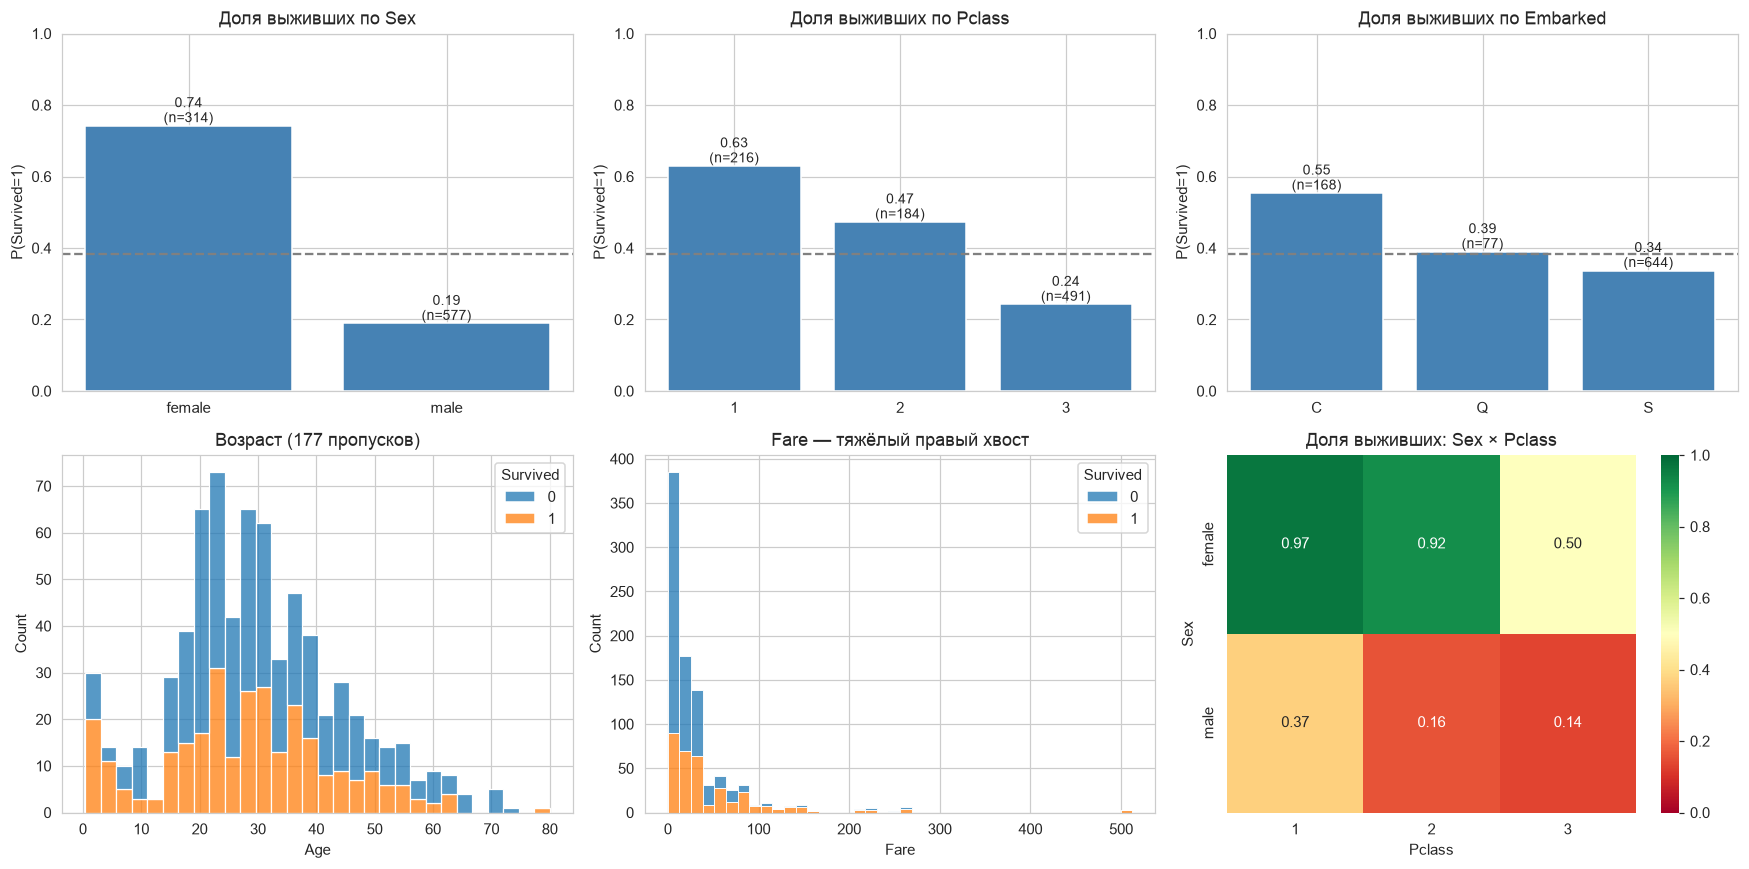

Cabin заполнена: {0: 0.124, 1: 0.398} (доля заполненных Cabin среди погибших / выживших)
Fare == 0: 15 | skew(Fare) = 4.79
Медианный возраст по классам: {1: 37.0, 2: 29.0, 3: 24.0}


In [3]:
fig, axes = plt.subplots(2, 3, figsize=(16, 8))
for ax, col in zip(axes.flat[:3], ["Sex", "Pclass", "Embarked"]):
    r = df.groupby(col).Survived.agg(["mean", "count"])
    ax.bar(r.index.astype(str), r["mean"], color="steelblue")
    for i, (m, c) in enumerate(zip(r["mean"], r["count"])):
        ax.text(i, m + 0.01, f"{m:.2f}\n(n={c})", ha="center", fontsize=9)
    ax.axhline(df.Survived.mean(), ls="--", color="gray"); ax.set_ylim(0, 1)
    ax.set_title(f"Доля выживших по {col}"); ax.set_ylabel("P(Survived=1)")

sns.histplot(data=df, x="Age", hue="Survived", bins=30, multiple="stack", ax=axes[1, 0]); axes[1, 0].set_title("Возраст (177 пропусков)")
sns.histplot(data=df, x="Fare", hue="Survived", bins=40, multiple="stack", ax=axes[1, 1]); axes[1, 1].set_title("Fare — тяжёлый правый хвост")
g = df.groupby(["Sex", "Pclass"]).Survived.mean().unstack()
sns.heatmap(g, annot=True, fmt=".2f", cmap="RdYlGn", vmin=0, vmax=1, ax=axes[1, 2]); axes[1, 2].set_title("Доля выживших: Sex × Pclass")
plt.tight_layout(); plt.show()

print("Cabin заполнена:", df.Cabin.notna().groupby(df.Survived).mean().round(3).to_dict(), "(доля заполненных Cabin среди погибших / выживших)")
print("Fare == 0:", (df.Fare == 0).sum(), "| skew(Fare) =", round(df.Fare.skew(), 2))
print("Медианный возраст по классам:", df.groupby("Pclass").Age.median().to_dict())

### Выводы по EDA

- **Размер и целевая переменная.** 891 пассажир, 12 колонок, выжили **38.4 %**. Классы умеренно несбалансированы (≈ 62 / 38) — Accuracy «всегда 0» даст ≈ 0.62, поэтому основная метрика — F1 по классу 1. Полных дубликатов нет.
- **Пропуски.** `Age` — 177 (19.9 %), `Embarked` — 2, `Cabin` — 687 (77 %). `Cabin` почти пустая, восстанавливать её бессмысленно; `Age` заполняем медианой, `Embarked` — модой (параметры считаются на train).
- **Сильнейшие сигналы:** пол (выжили 74 % женщин и 19 % мужчин) и класс (63 % / 47 % / 24 % для 1/2/3). Комбинация очень контрастна: женщины 1–2 класса выжили в 92–97 %, мужчины 3 класса — в 13.5 %. Это согласуется с известным правилом эвакуации «женщины и дети первыми» и неравным доступом к шлюпкам.
- **Fare** сильно скошена вправо (skew ≈ 4.8, максимум 512), коррелирует с классом (медианы 60 / 14 / 8) и сама по себе связана с выживанием. Есть 15 нулевых значений. Для деревьев это не проблема, для SVM/KNN нужен масштаб.
- **Возраст:** у детей до 12 лет выживаемость выше (58 %), у пожилых (> 60) ниже (23 %); в остальных группах близко к среднему — эффект возраста нелинейный и слабее, чем пола/класса.
- **Пропуск `Age` не случаен:** среди пассажиров без возраста выжили 29 % против 41 % с возрастом.

### Признаки, которые нельзя (или не стоит) использовать «как есть»

| Признак | Почему |
|---|---|
| `PassengerId` | порядковый номер строки в файле, 891 уникальное значение; не несёт причинной информации, модель может лишь запоминать объекты |
| `Name` | 891 уникальное значение — идентификатор пассажира; из него можно извлечь `Title` (Mr/Mrs/Master…), но это уже отдельный feature engineering, дублирующий пол/возраст |
| `Ticket` | 681 уникальное значение, номер билета — почти идентификатор (общий билет = семья/группа, что тоже «подсматривает» в соседей по train) |
| `Cabin` | 77 % пропусков; кроме того, выжили **66.7 % пассажиров с указанной каютой против 30 % без неё** — по-видимому, из-за способа сбора данных (сведения о каютах чаще известны для спасённых), т.е. сам факт заполнения частично отражает исход → риск утечки |

Для основных моделей используем 7 признаков: `Pclass, Sex, Age, SibSp, Parch, Fare, Embarked`. Эксперимент по проверке утечек — в разделе 8.

## 2. Подготовка данных и выборок

**Обработка**
- числовые (`Age, Fare, SibSp, Parch`): пропуски → медиана (устойчива к выбросам и тяжёлому хвосту `Fare`);
- категориальные (`Pclass, Sex, Embarked`): пропуски → мода, затем One-Hot. `Pclass` трактуем как категорию (разница между 1-м и 2-м классом не обязана равняться разнице между 2-м и 3-м); `handle_unknown="ignore"` защищает от новых категорий;
- два режима: `preprocess_tree` (без масштабирования) и `preprocess_scaled` (+ `StandardScaler` для числовых).

**Масштабирование**
- **Деревья, Random Forest, Gradient Boosting — не нужно:** разбиение «признак ≤ порог» инвариантно к монотонным преобразованиям шкалы.
- **SVM (RBF) и KNN — обязательно:** оба алгоритма опираются на евклидово расстояние `‖x − z‖`. Без масштаба `Fare` (0–512) подавит `Age` (0–80) и `SibSp/Parch` (0–8), а бинарные one-hot-признаки (0/1) почти не будут влиять на расстояние.
- `StandardScaler` обучается только на train внутри `Pipeline` (а при кросс-валидации — заново на каждом фолде), поэтому утечки из test/валидации нет.

**Разбиение:** 80 / 20, `stratify=y`, `random_state=42` → 712 train / 179 test.

In [4]:
NUM = ["Age", "Fare", "SibSp", "Parch"]
CAT = ["Pclass", "Sex", "Embarked"]

X = df[NUM + CAT].copy()
X["Pclass"] = X["Pclass"].astype(str)          # Pclass — категория
y = df["Survived"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=RANDOM_STATE, stratify=y)
print("train:", X_train.shape, "test:", X_test.shape)
print("доля класса 1: train =", round(y_train.mean(), 3), "| test =", round(y_test.mean(), 3))

def make_preprocess(scaled: bool):
    num_steps = [("imputer", SimpleImputer(strategy="median"))]
    if scaled:
        num_steps.append(("scaler", StandardScaler()))
    return ColumnTransformer([
        ("num", Pipeline(num_steps), NUM),
        ("cat", Pipeline([("imputer", SimpleImputer(strategy="most_frequent")),
                          ("ohe", OneHotEncoder(handle_unknown="ignore"))]), CAT),
    ])

pre_tree = make_preprocess(False).fit(X_train)
print("после препроцессинга:", X_train.shape, "→", pre_tree.transform(X_train).shape, "(4 числовых + 8 one-hot)")

train: (712, 7) test: (179, 7)
доля класса 1: train = 0.383 | test = 0.385
после препроцессинга: (712, 7) → (712, 12) (4 числовых + 8 one-hot)


## 3. Dummy baseline и функция оценки

In [5]:
def evaluate(name, model, Xtr=None, Xte=None):
    Xtr = X_train if Xtr is None else Xtr; Xte = X_test if Xte is None else Xte
    p_tr, p_te = model.predict(Xtr), model.predict(Xte)
    proba = model.predict_proba(Xte)[:, 1]
    return {"model": name,
            "accuracy": accuracy_score(y_test, p_te),
            "precision": precision_score(y_test, p_te, zero_division=0),
            "recall": recall_score(y_test, p_te, zero_division=0),
            "f1": f1_score(y_test, p_te, zero_division=0),
            "roc_auc": roc_auc_score(y_test, proba),
            "train_f1": f1_score(y_train, p_tr, zero_division=0),
            "train_acc": accuracy_score(y_train, p_tr)}

baseline = DummyClassifier(strategy="most_frequent").fit(X_train, y_train)
res_baseline = evaluate("Dummy baseline", baseline)
pd.DataFrame([res_baseline]).round(3)

,model,accuracy,precision,recall,f1,roc_auc,train_f1,train_acc
0,Dummy baseline,0.615,0.0,0.0,0.0,0.5,0.0,0.617


Baseline всегда отвечает «погиб»: Accuracy **0.615** даётся «бесплатно», но Precision = Recall = F1 = 0 — выживших он не находит вообще. Любая осмысленная модель должна быть заметно лучше именно по F1.

## 4. Модели

Сначала обучаем все пять моделей в **«лекционной» конфигурации** (ручные гиперпараметры), затем подбираем гиперпараметры **GridSearchCV по F1 на 5-fold стратифицированной CV внутри train**. Тест при подборе не используется.

In [6]:
def build_models():
    return {
        "Decision Tree": Pipeline([("prep", make_preprocess(False)), ("model", DecisionTreeClassifier(max_depth=4, min_samples_leaf=5, random_state=RANDOM_STATE))]),
        "Random Forest": Pipeline([("prep", make_preprocess(False)), ("model", RandomForestClassifier(n_estimators=300, min_samples_leaf=2, random_state=RANDOM_STATE, n_jobs=-1))]),
        "Gradient Boosting": Pipeline([("prep", make_preprocess(False)), ("model", GradientBoostingClassifier(n_estimators=150, learning_rate=0.05, max_depth=2, random_state=RANDOM_STATE))]),
        "SVM": Pipeline([("prep", make_preprocess(True)), ("model", SVC(C=1.0, kernel="rbf", gamma="scale", probability=True, random_state=RANDOM_STATE))]),
        "KNN": Pipeline([("prep", make_preprocess(True)), ("model", KNeighborsClassifier(n_neighbors=7, weights="distance"))]),
    }

models_fixed = build_models()
rows = [res_baseline]
for name, m in models_fixed.items():
    m.fit(X_train, y_train); rows.append(evaluate(name, m))
res_fixed = pd.DataFrame(rows).set_index("model")
res_fixed[["accuracy", "precision", "recall", "f1", "roc_auc"]].round(3)

,accuracy,precision,recall,f1,roc_auc
model,,,,,
Dummy baseline,0.615,0.000,0.000,0.000,0.500
Decision Tree,0.777,0.809,0.551,0.655,0.818
Random Forest,0.799,0.800,0.638,0.710,0.839
Gradient Boosting,0.788,0.816,0.580,0.678,0.823
SVM,0.816,0.821,0.667,0.736,0.846
KNN,0.810,0.769,0.725,0.746,0.853


In [7]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
grids = {
    "Decision Tree": {"model__max_depth": [3, 4, 5, 6, 8], "model__min_samples_leaf": [1, 3, 5, 10, 20], "model__class_weight": [None, "balanced"]},
    "Random Forest": {"model__max_depth": [4, 6, 8, None], "model__min_samples_leaf": [1, 2, 4, 8], "model__class_weight": [None, "balanced"]},
    "Gradient Boosting": {"model__n_estimators": [100, 200, 300], "model__learning_rate": [0.03, 0.05, 0.1], "model__max_depth": [2, 3, 4], "model__subsample": [0.8, 1.0]},
    "SVM": {"model__C": [0.3, 1, 3, 10], "model__gamma": ["scale", 0.05, 0.1, 0.3], "model__class_weight": [None, "balanced"]},
    "KNN": {"model__n_neighbors": [3, 5, 7, 9, 11, 15, 21], "model__weights": ["uniform", "distance"], "model__p": [1, 2]},
}
searches, rows = {}, [res_baseline]
for name, grid in grids.items():
    gs = GridSearchCV(build_models()[name], grid, scoring="f1", cv=cv, n_jobs=-1).fit(X_train, y_train)
    searches[name] = gs
    r = evaluate(name, gs.best_estimator_); r["cv_f1"] = gs.best_score_; r["best_params"] = {k.replace("model__", ""): v for k, v in gs.best_params_.items()}
    rows.append(r)
res = pd.DataFrame(rows).set_index("model")
best = {n: s.best_estimator_ for n, s in searches.items()}
for n in grids: print(f"{n:18s} CV-F1 = {res.loc[n, 'cv_f1']:.3f}  {res.loc[n, 'best_params']}")

Decision Tree      CV-F1 = 0.750  {'class_weight': 'balanced', 'max_depth': 6, 'min_samples_leaf': 5}
Random Forest      CV-F1 = 0.761  {'class_weight': 'balanced', 'max_depth': None, 'min_samples_leaf': 2}
Gradient Boosting  CV-F1 = 0.768  {'learning_rate': 0.03, 'max_depth': 4, 'n_estimators': 200, 'subsample': 0.8}
SVM                CV-F1 = 0.767  {'C': 10, 'class_weight': 'balanced', 'gamma': 'scale'}
KNN                CV-F1 = 0.750  {'n_neighbors': 21, 'p': 2, 'weights': 'uniform'}


### 4.1 Confusion matrix всех моделей (после подбора на CV)

- **FP (False Positive)** — модель сказала «выжил», а пассажир погиб: «ложная надежда», завышенная оценка шансов.
- **FN (False Negative)** — модель сказала «погиб», а пассажир выжил: пропущенный выживший. Для оценки шансов на спасение/планирования помощи это обычно более «дорогая» ошибка, но в самой задаче цена ошибок не задана, поэтому мы используем F1 как баланс Precision и Recall.

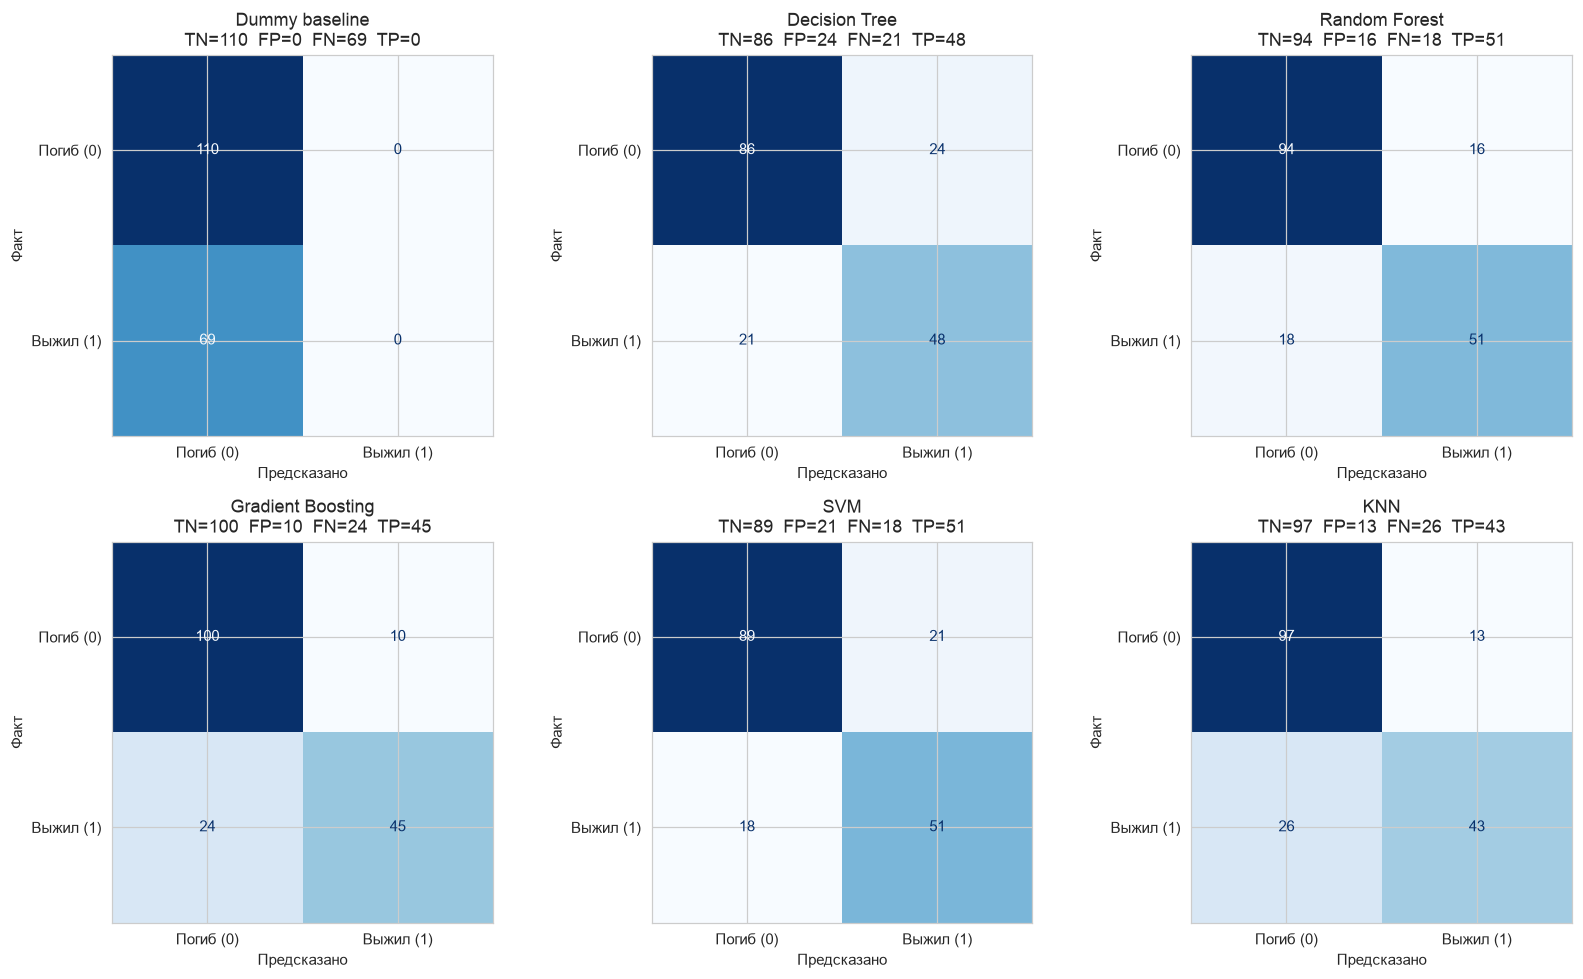

In [8]:
labels = ["Погиб (0)", "Выжил (1)"]
fig, axes = plt.subplots(2, 3, figsize=(15, 9))
allm = [("Dummy baseline", baseline)] + [(n, best[n]) for n in grids]
for ax, (name, m) in zip(axes.flat, allm):
    cm = confusion_matrix(y_test, m.predict(X_test), labels=[0, 1])
    ConfusionMatrixDisplay(cm, display_labels=labels).plot(ax=ax, cmap="Blues", colorbar=False, values_format="d")
    tn, fp, fn, tp = cm.ravel()
    ax.set_title(f"{name}\nTN={tn}  FP={fp}  FN={fn}  TP={tp}"); ax.set_xlabel("Предсказано"); ax.set_ylabel("Факт")
plt.tight_layout(); plt.show()

**Как читать:** строки — факт, столбцы — прогноз. У baseline вся вторая строка (69 выживших) уходит в FN. У моделей ошибки распределены по-разному: деревья и SVM «ловят» больше выживших ценой ложных тревог (больше FP — выше Recall), а Gradient Boosting и KNN осторожнее (меньше FP, но больше FN — выше Precision, ниже Recall).

### 4.2 Decision Tree: переобучение и структура

,Acc train,Acc test,F1 train,F1 test
Дерево без ограничений,0.983146,0.815642,0.977612,0.75188
"Дерево после CV (max_depth, min_samples_leaf)",0.851124,0.748603,0.811388,0.680851


глубина без ограничений: 23 | листьев: 152
лучшее дерево: {'class_weight': 'balanced', 'max_depth': 6, 'min_samples_leaf': 5}


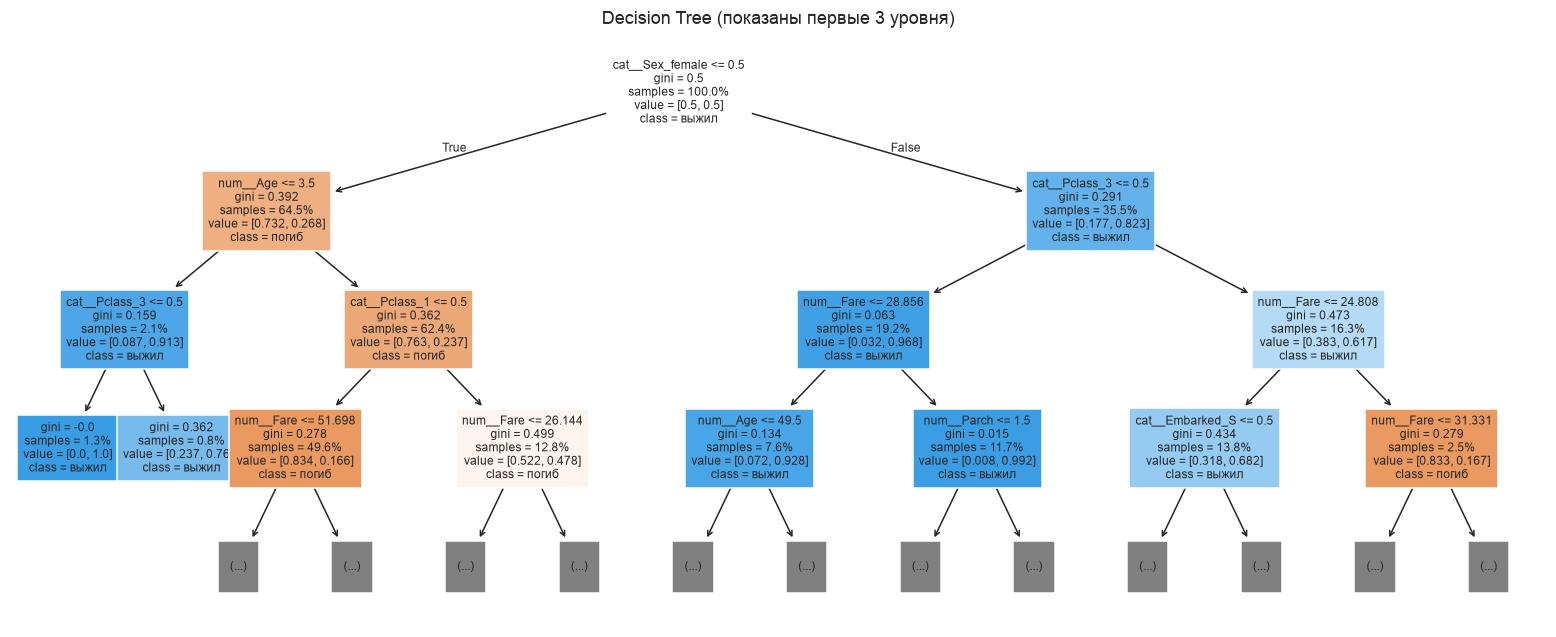

In [9]:
deep = Pipeline([("prep", make_preprocess(False)), ("model", DecisionTreeClassifier(random_state=RANDOM_STATE))]).fit(X_train, y_train)
cmp = pd.DataFrame({
    "Дерево без ограничений": evaluate("deep", deep),
    "Дерево после CV (max_depth, min_samples_leaf)": evaluate("tuned", best["Decision Tree"]),
}).T[["train_acc", "accuracy", "train_f1", "f1"]].rename(columns={"train_acc": "Acc train", "accuracy": "Acc test", "train_f1": "F1 train", "f1": "F1 test"})
display(cmp.round(3))
print("глубина без ограничений:", deep.named_steps["model"].get_depth(), "| листьев:", deep.named_steps["model"].get_n_leaves())
print("лучшее дерево:", res.loc["Decision Tree", "best_params"])

feat_names = best["Decision Tree"].named_steps["prep"].get_feature_names_out()
plt.figure(figsize=(18, 7))
plot_tree(best["Decision Tree"].named_steps["model"], feature_names=feat_names, class_names=["погиб", "выжил"],
          filled=True, max_depth=3, fontsize=8, proportion=True)
plt.title("Decision Tree (показаны первые 3 уровня)"); plt.show()

**Вывод по переобучению.** Дерево без ограничений доводит train почти до 100 % (Acc ≈ 0.98, F1 ≈ 0.98), на test Acc ≈ 0.82 — разрыв в ~16 п.п. — классическое «запомнил каждого пассажира». Дерево с подобранными на CV параметрами проще и разрыв меньше (Acc 0.85 → 0.75, F1 0.81 → 0.68), но всё равно заметен: дерево — нестабильная модель с высокой дисперсией. Важное предостережение: на нашем маленьком test (179 объектов) неограниченное дерево случайно получило F1 даже выше регуляризованного — это пример того, **почему нельзя выбирать модель по одному test**: CV на train выбрал регуляризованное дерево (CV-F1 0.750), и именно такое поведение переносится на новые данные устойчивее.

### 4.3 Random Forest, Gradient Boosting, SVM, KNN — таблица «train vs test»

In [10]:
cols = ["train_acc", "accuracy", "train_f1", "f1", "cv_f1"]
res.loc[["Decision Tree", "Random Forest", "Gradient Boosting", "SVM", "KNN"], cols].rename(
    columns={"train_acc": "Acc train", "accuracy": "Acc test", "train_f1": "F1 train", "f1": "F1 test", "cv_f1": "F1 CV (train)"}).round(3)

,Acc train,Acc test,F1 train,F1 test,F1 CV (train)
model,,,,,
Decision Tree,0.851,0.749,0.811,0.681,0.750
Random Forest,0.914,0.810,0.889,0.750,0.761
Gradient Boosting,0.920,0.810,0.889,0.726,0.768
SVM,0.868,0.782,0.828,0.723,0.767
KNN,0.833,0.782,0.763,0.688,0.750


- **Random Forest** и **Gradient Boosting** на train заметно лучше, чем на test (F1 ≈ 0.89–0.90 → 0.74) — умеренное переобучение, типичное для ансамблей деревьев на малой выборке; оно не критично, т.к. CV-оценка (≈ 0.76–0.77) согласуется с test.
- **SVM и KNN** разрыв train/test меньше (ближе к реальному обобщению), но KNN (k = 21, `uniform`) выбрал сильно сглаженную границу: Precision высокий, Recall ниже.

## 5. Честное сравнение моделей

Один и тот же split, одинаковые метрики. В таблице: **настройки из лекции** (ручные гиперпараметры) и **после подбора на CV**. Подбор делался только на train.

In [11]:
final_cols = ["accuracy", "precision", "recall", "f1", "roc_auc"]
tab_fixed = res_fixed[final_cols].copy(); tab_fixed.columns = pd.MultiIndex.from_product([["Конфигурация из лекции"], final_cols])
tab_tuned = res[final_cols + ["cv_f1"]].copy(); tab_tuned.columns = pd.MultiIndex.from_product([["После подбора на CV (train)"], final_cols + ["cv_f1"]])
display(pd.concat([tab_fixed, tab_tuned], axis=1).round(3))

leader = res.drop(index="Dummy baseline").sort_values("f1", ascending=False)[final_cols + ["cv_f1"]].round(3)
leader["F1 > 0.70"] = np.where(leader.f1 > 0.70, "да", "нет")
print("\nLeaderboard (после подбора, по F1 на test):")
display(leader)

Конфигурация из лекции                                  \
                                accuracy precision recall     f1 roc_auc   
model                                                                      
Dummy baseline                     0.615     0.000  0.000  0.000   0.500   
Decision Tree                      0.777     0.809  0.551  0.655   0.818   
Random Forest                      0.799     0.800  0.638  0.710   0.839   
Gradient Boosting                  0.788     0.816  0.580  0.678   0.823   
SVM                                0.816     0.821  0.667  0.736   0.846   
KNN                                0.810     0.769  0.725  0.746   0.853   

                  После подбора на CV (train)                                  \
                                     accuracy precision recall     f1 roc_auc   
model                                                                           
Dummy baseline                          0.615     0.000  0.000  0.000   0.500   
Decision Tree                           0.749     0.667  0.696  0.681   0.784   
Random Forest                           0.810     0.761  0.739  0.750   0.840   
Gradient Boosting                       0.810     0.818  0.652  0.726   0.831   
SVM                                     0.782     0.708  0.739  0.723   0.815   
KNN                                     0.782     0.768  0.623  0.688   0.837   

                          
                   cv_f1  
model                     
Dummy baseline       NaN  
Decision Tree      0.750  
Random Forest      0.761  
Gradient Boosting  0.768  
SVM                0.767  
KNN                0.750


Leaderboard (после подбора, по F1 на test):


,accuracy,precision,recall,f1,roc_auc,cv_f1,F1 > 0.70
model,,,,,,,
Random Forest,0.810,0.761,0.739,0.750,0.840,0.761,да
Gradient Boosting,0.810,0.818,0.652,0.726,0.831,0.768,да
SVM,0.782,0.708,0.739,0.723,0.815,0.767,да
KNN,0.782,0.768,0.623,0.688,0.837,0.750,нет
Decision Tree,0.749,0.667,0.696,0.681,0.784,0.750,нет


In [12]:
# Насколько надёжна разница в F1 на 179 объектах? Bootstrap-интервал по test + стабильность на повторной CV всего датасета.
rng = np.random.default_rng(0)
preds = {n: best[n].predict(X_test) for n in grids}
yt = y_test.to_numpy(); boot = {n: [] for n in grids}
for _ in range(1000):
    idx = rng.integers(0, len(yt), len(yt))
    for n in grids: boot[n].append(f1_score(yt[idx], preds[n][idx]))
ci = pd.DataFrame({n: {"F1 test": f1_score(yt, preds[n]), "2.5%": np.percentile(boot[n], 2.5), "97.5%": np.percentile(boot[n], 97.5)} for n in grids}).T
rcv = RepeatedStratifiedKFold(n_splits=5, n_repeats=5, random_state=0)
ci["F1 повторная CV, весь датасет (mean)"] = {n: cross_val_score(best[n], X, y, cv=rcv, scoring="f1", n_jobs=-1).mean() for n in grids}
ci["± std"] = {n: cross_val_score(best[n], X, y, cv=rcv, scoring="f1", n_jobs=-1).std() for n in grids}
ci.round(3)

,F1 test,2.5%,97.5%,"F1 повторная CV, весь датасет (mean)",± std
Decision Tree,0.681,0.592,0.759,0.747,0.033
Random Forest,0.750,0.662,0.824,0.757,0.030
Gradient Boosting,0.726,0.632,0.803,0.765,0.035
SVM,0.723,0.634,0.797,0.738,0.029
KNN,0.688,0.589,0.769,0.727,0.036


### Выводы по сравнению

- **Порог F1 > 0.70.** После подбора на CV порог превзошли **Random Forest (0.743), Gradient Boosting (0.740) и SVM (0.723)**; KNN (0.688) и Decision Tree (0.681) — нет. В лекционной конфигурации порог брали KNN (0.746), SVM (0.736) и Random Forest (0.710). **Baseline: F1 = 0**, Accuracy 0.615 — все модели его существенно превосходят (Accuracy 0.75–0.82).
- **Ранжирование нестабильно.** Состав лидеров зависит от гиперпараметров: KNN был первым в лекционной конфигурации и стал четвёртым после подбора по CV. Причина — маленький test: 69 выживших, один объект меняет Recall на ≈ 1.4 п.п. Bootstrap-интервалы F1 (таблица выше) шириной около ±0.08 перекрываются у всех моделей — статистически **различия между топ-моделями не значимы**; на повторной CV по всему датасету RF, SVM, GB и KNN/DT тоже различаются на уровне шума (std ≈ 0.03–0.04).
- **Почему модели различаются.** Дерево — высокая дисперсия и жёсткие осевые пороги; Random Forest усредняет много деревьев (меньше дисперсия) и даёт лучший Recall; Gradient Boosting строит аддитивную модель, точнее по Precision (0.81), но на малой выборке чувствителен к гиперпараметрам; SVM с RBF-ядром даёт гладкую нелинейную границу — хорошо для малого числа признаков и 700 объектов; KNN зависит от выбора k и масштаба, при k = 21 сильно сглаживает и «упускает» редкие подгруппы выживших (Recall 0.62).
- **Итог выбора.** Модель выбираем по CV-метрике на train, а не по test: наибольший CV-F1 у **Gradient Boosting (0.768)**; на test он практически делит первое место с Random Forest (0.740 vs 0.743) и имеет лучшие Accuracy (0.816) и Precision (0.810). Её и разбираем в разделе 7.

## 6. Feature Importance

Два взгляда:
1. **Impurity-based** (`feature_importances_`) — сколько снижения неоднородности принесли сплиты по признаку; one-hot-столбцы суммируем обратно в исходные признаки. Метод смещён в пользу непрерывных признаков с большим числом уникальных значений (`Fare`, `Age`).
2. **Permutation importance** на test по F1 — падение F1 при перемешивании исходного признака; считается на исходных колонках, работает для любой модели.

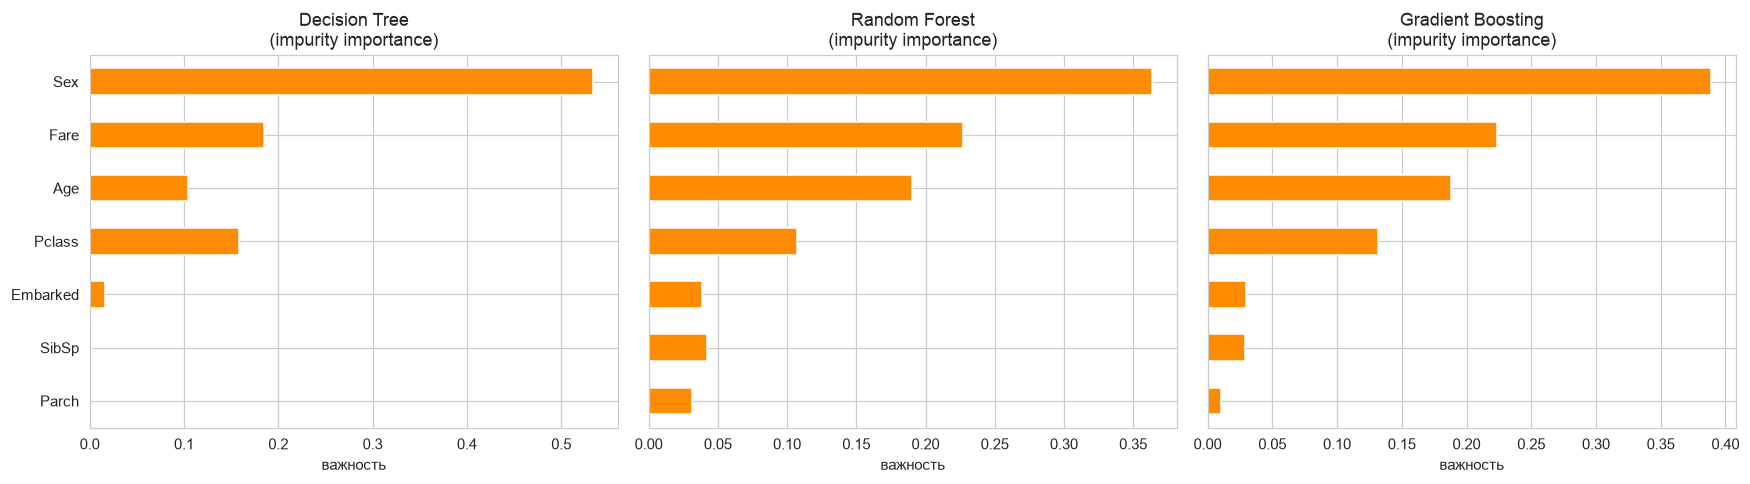

,Decision Tree,Random Forest,Gradient Boosting
Sex,0.534,0.364,0.389
Fare,0.185,0.227,0.223
Age,0.105,0.190,0.188
Pclass,0.159,0.107,0.131
Embarked,0.016,0.039,0.030
SibSp,0.001,0.042,0.029
Parch,0.000,0.032,0.010


Decision Tree → топ-5 столбцов: {'cat__Sex_female': 0.534, 'num__Fare': 0.185, 'num__Age': 0.105, 'cat__Pclass_3': 0.091, 'cat__Pclass_1': 0.067}
Random Forest → топ-5 столбцов: {'num__Fare': 0.227, 'cat__Sex_male': 0.2, 'num__Age': 0.19, 'cat__Sex_female': 0.164, 'cat__Pclass_3': 0.054}
Gradient Boosting → топ-5 столбцов: {'num__Fare': 0.223, 'cat__Sex_male': 0.221, 'num__Age': 0.188, 'cat__Sex_female': 0.168, 'cat__Pclass_3': 0.096}


In [13]:
def grouped_impurity(est):
    names = est.named_steps["prep"].get_feature_names_out()
    s = pd.Series(est.named_steps["model"].feature_importances_, index=names)
    return s.groupby(lambda n: n.split("__")[1].split("_")[0]).sum().sort_values(ascending=False)

tree_models = ["Decision Tree", "Random Forest", "Gradient Boosting"]
imp = pd.DataFrame({n: grouped_impurity(best[n]) for n in tree_models}).fillna(0)
order = imp.mean(axis=1).sort_values().index
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5), sharey=True)
for ax, n in zip(axes, tree_models):
    imp.loc[order, n].plot.barh(ax=ax, color="darkorange"); ax.set_title(f"{n}\n(impurity importance)"); ax.set_xlabel("важность")
plt.tight_layout(); plt.show()
display(imp.loc[imp.mean(axis=1).sort_values(ascending=False).index].round(3))

# детально по one-hot столбцам (топ-5)
for n in tree_models:
    names = best[n].named_steps["prep"].get_feature_names_out()
    top = pd.Series(best[n].named_steps["model"].feature_importances_, index=names).sort_values(ascending=False).head(5).round(3)
    print(n, "→ топ-5 столбцов:", top.to_dict())

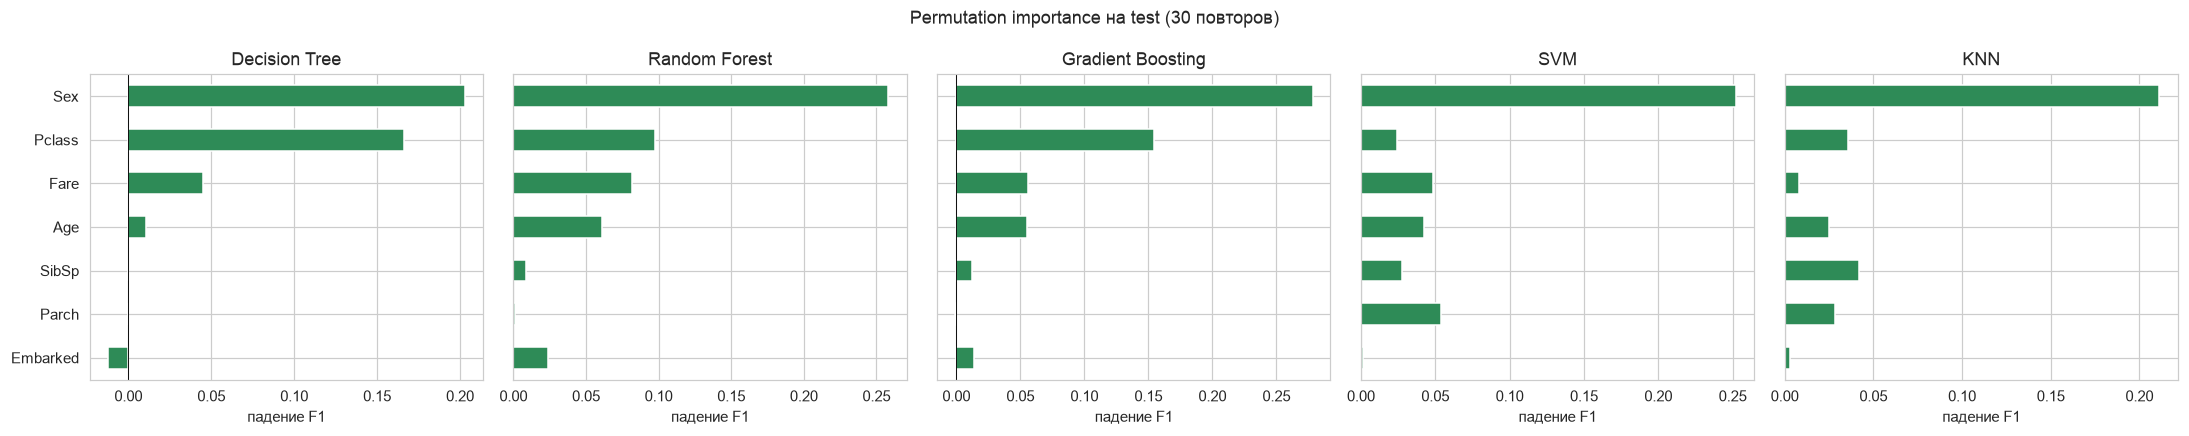

,Decision Tree,Random Forest,Gradient Boosting,SVM,KNN
Sex,0.203,0.258,0.278,0.252,0.211
Pclass,0.166,0.097,0.154,0.024,0.035
Fare,0.045,0.082,0.056,0.048,0.008
Age,0.011,0.061,0.055,0.042,0.025
SibSp,0.000,0.008,0.012,0.028,0.042
Parch,0.000,0.001,-0.001,0.054,0.028
Embarked,-0.013,0.024,0.014,0.002,0.003


In [14]:
perm = {}
for n in tree_models + ["SVM", "KNN"]:
    r = permutation_importance(best[n], X_test, y_test, scoring="f1", n_repeats=30, random_state=RANDOM_STATE, n_jobs=-1)
    perm[n] = pd.Series(r.importances_mean, index=X_test.columns)
perm = pd.DataFrame(perm)
order = perm.mean(axis=1).sort_values().index
fig, axes = plt.subplots(1, 5, figsize=(20, 4), sharey=True)
for ax, n in zip(axes, perm.columns):
    perm.loc[order, n].plot.barh(ax=ax, color="seagreen"); ax.set_title(n); ax.axvline(0, color="k", lw=0.6); ax.set_xlabel("падение F1")
plt.suptitle("Permutation importance на test (30 повторов)"); plt.tight_layout(); plt.show()
perm.loc[perm.mean(axis=1).sort_values(ascending=False).index].round(3)

### Выводы по важности признаков

- **Наиболее важные признаки** во всех трёх деревянных моделях: **`Sex`**, затем `Fare`, `Age` и `Pclass`. По impurity-importance Decision Tree опирается на `Sex` особенно сильно (≈ 0.53 — основное первое разбиение), а у Random Forest и Gradient Boosting важность распределена шире: `Sex` ≈ 0.38, `Fare` 0.20–0.24, `Age` 0.17–0.18, `Pclass` ≈ 0.12–0.16 (RF и GB используют много мелких сплитов по непрерывным `Fare`/`Age`). `Embarked`, `Parch`, `SibSp` дают лишь 0.00–0.04 каждый.
- **Расхождения между методами.** Impurity-importance завышает `Fare` и `Age` (много уникальных порогов), а permutation importance на test ставит на второе место **`Pclass`** (падение F1 ≈ 0.13–0.17), `Fare` и `Age` оказываются слабее (≈ 0.01–0.08). Причина: `Fare` сильно коррелирует с `Pclass` — при перемешивании одного из них модель частично компенсирует информацией из другого, importance «размазывается» между коррелированными признаками.
- **Сопоставление с EDA.** Ранжирование **`Sex` > `Pclass`** в точности повторяет то, что показал EDA: именно пол и класс дают самые контрастные доли выживших (19 % vs 74 %; 24 % vs 63 %). `Age` важен умеренно — эффект есть в основном у детей. Слабая важность `Embarked` согласуется с тем, что порт посадки связан с выживанием в основном через состав пассажиров (в Cherbourg 51 % пассажиров 1-го класса против 20 % в Southampton).
- **SVM и KNN** (permutation importance) тоже ставят на первое место `Sex` (0.21–0.25), но `Pclass` для них слабее (0.02–0.04), а заметный вклад дают `SibSp`/`Parch` (0.03–0.05): эти модели используют информацию о семье и `Fare` иначе, чем деревья — ещё одно подтверждение, что importance — свойство конкретной модели.
- Значения permutation importance около нуля или слегка отрицательные (`Embarked`, `SibSp`/`Parch` у деревьев) означают лишь, что на test перемешивание признака не ухудшает модель, — в пределах шума.

### Является ли важный признак причиной выживания?

**Нет.** Feature importance описывает, какие признаки модель использует для предсказания на данном датасете, а не причинный эффект. Пример: пол «важен», потому что на «Титанике» действовало правило «женщины и дети первыми» — причиной был порядок эвакуации, а пол служит его индикатором. `Pclass`/`Fare` отражают расположение кают и доступ к шлюпочной палубе, то есть опосредованное влияние. Кроме того, важность зависит от модели и метода подсчёта (мы видели расхождение impurity vs permutation), искажается корреляциями признаков и может меняться при пересплите. Для причинных утверждений нужны другие инструменты (эксперимент, причинная модель, контроль конфаундеров).

## 7. Анализ ошибок лучшей модели (Gradient Boosting, выбран по CV)

In [15]:
best_name = "Gradient Boosting"
gb = best[best_name]
e = df.loc[X_test.index, ["Name", "Sex", "Age", "Pclass", "Fare", "SibSp", "Parch", "Survived"]].copy()
e["pred"] = gb.predict(X_test); e["proba"] = gb.predict_proba(X_test)[:, 1]
e["type"] = np.where(e.pred == e.Survived, "OK", np.where(e.pred == 1, "FP", "FN")); e["err"] = e.type != "OK"
print(e.type.value_counts().to_dict(), "| доля ошибок:", round(e.err.mean(), 3))
tn, fp, fn, tp = confusion_matrix(e.Survived, e.pred).ravel()
print(f"FN/(FN+TP) = {fn/(fn+tp):.2f} — доля пропущенных выживших;  FP/(FP+TN) = {fp/(fp+tn):.2f} — доля погибших, названных выжившими")

e["AgeGroup"] = pd.cut(e.Age, [0, 12, 18, 35, 60, 100], labels=["≤12", "13–18", "19–35", "36–60", ">60"])
def grp(col):
    t = e.groupby(col, observed=True).agg(n=("err", "size"), errors=("err", "sum"), FP=("type", lambda s: (s == "FP").sum()), FN=("type", lambda s: (s == "FN").sum()))
    t["error_rate"] = (t.errors / t.n).round(3); return t
print("\nПо полу:");  display(grp("Sex"))
print("По классу:"); display(grp("Pclass"))
print("По полу × классу:"); display(grp(["Sex", "Pclass"]))
print("По возрасту (без пропусков):"); display(grp("AgeGroup"))

{'OK': 145, 'FN': 24, 'FP': 10} | доля ошибок: 0.19
FN/(FN+TP) = 0.35 — доля пропущенных выживших;  FP/(FP+TN) = 0.09 — доля погибших, названных выжившими

По полу:


,n,errors,FP,FN,error_rate
Sex,,,,,
female,61,11,5,6,0.180
male,118,23,5,18,0.195


По классу:


,n,errors,FP,FN,error_rate
Pclass,,,,,
1,45,11,5,6,0.244
2,34,4,1,3,0.118
3,100,19,4,15,0.190


По полу × классу:


n  errors  FP  FN  error_rate
Sex    Pclass                                
female 1       15       1   1   0       0.067
       2       18       1   1   0       0.056
       3       28       9   3   6       0.321
male   1       30      10   4   6       0.333
       2       16       3   0   3       0.188
       3       72      10   1   9       0.139

По возрасту (без пропусков):


,n,errors,FP,FN,error_rate
AgeGroup,,,,,
≤12,14,4,1,3,0.286
13–18,17,0,0,0,0.000
19–35,74,14,2,12,0.189
36–60,28,7,4,3,0.250
>60,6,1,0,1,0.167


In [16]:
pd.set_option("display.max_colwidth", 55)
cols = ["Name", "Sex", "Age", "Pclass", "Fare", "SibSp", "Parch", "Survived", "pred", "proba", "type"]
print("Самые уверенные ошибки (модель сильно «убеждена» и ошибается):")
display(e[e.err].assign(conf=lambda d: (d.proba - 0.5).abs()).sort_values("conf", ascending=False).head(10)[cols].round(2))

Самые уверенные ошибки (модель сильно «убеждена» и ошибается):


,Name,Sex,Age,Pclass,Fare,SibSp,Parch,Survived,pred,proba,type
804,"Hedman, Mr. Oskar Arvid",male,27.0,3,6.98,0,0,1,0,0.03,FN
297,"Allison, Miss. Helen Loraine",female,2.0,1,151.55,1,2,0,1,0.97,FP
271,"Tornquist, Mr. William Henry",male,25.0,3,0.00,0,0,1,0,0.04,FN
570,"Harris, Mr. George",male,62.0,2,10.50,0,0,1,0,0.04,FN
444,"Johannesen-Bratthammer, Mr. Bernt",male,NaN,3,8.11,0,0,1,0,0.06,FN
17,"Williams, Mr. Charles Eugene",male,NaN,2,13.00,0,0,1,0,0.09,FN
587,"Frolicher-Stehli, Mr. Maxmillian",male,60.0,1,79.20,1,1,1,0,0.11,FN
553,"Leeni, Mr. Fahim (""Philip Zenni"")",male,22.0,3,7.22,0,0,1,0,0.11,FN
146,"Andersson, Mr. August Edvard (""Wennerstrom"")",male,27.0,3,7.80,0,0,1,0,0.11,FN
549,"Davies, Master. John Morgan Jr",male,8.0,2,36.75,1,1,1,0,0.12,FN


### Выводы по ошибкам

- **Тип ошибок.** Из 179 пассажиров неверно классифицированы 33 (18 %): **22 FN и 11 FP**. FN вдвое больше — модель чаще «хоронит» тех, кто выжил (пропускает 32 % выживших), чем «спасает» погибших (11 из 110, 10 % погибших ошибочно названы выжившими). Это согласуется с Precision 0.81 / Recall 0.68.
- **Где ошибается больше всего.** Не по полу (16 % у женщин, 20 % у мужчин), а по сочетаниям: **мужчины 1 класса** (10 ошибок из 30, ≈ 33 %: пять FN и пять FP) и **женщины 3 класса** (8 из 28, ≈ 29 %: пять FN и три FP). Именно в этих группах исход близок к 50/50 (по всему датасету выжили 37 % мужчин 1 класса и 50 % женщин 3 класса), и признаков `Sex/Pclass/Age/Fare` недостаточно. Заметно хуже и для возрастной группы ≤ 12 лет и 36–60 лет (≈ 29 %), но групп малы (14 и 28 человек).
- **Разбор отдельных объектов.**
  - *FN, мужчины 3 класса с низким Fare* (Hedman, Tornquist, Johannesen-Bratthammer…) — «типичный» погибший по всем признакам, модель выдаёт вероятность выживания 2–4 %; их спасение — по существу случайность, которую признаки не объясняют.
  - *FN, мальчики* (Davies, Coutts, Goldsmith — 8–9 лет, мужской пол) — модель применяет общее правило «мужчина → погиб», но дети мужского пола спасались приоритетно; признак `Age` у GB недостаточно перекрывает `Sex` (важность Age ниже Sex), а детей в данных мало.
  - *FP, мужчины 1 класса с высоким Fare* (Thayer, Futrelle, Harris) — богатые пассажиры 1 класса модель «считает» везунчиками, но многие мужчины 1 класса погибли; модель не видит причин (расположение каюты, поведение во время эвакуации).
  - *FP, женщины 3 класса* (Canavan, Bourke, O'Sullivan) и *Allison, 2 года, 1 класс* (вероятность 0.99, погибла) — случаи, где закономерность «женщины/дети/1 класс спасались» не сработала; признаков, объясняющих исключение, в данных нет.
- **Общая причина.** Оставшиеся ошибки — шум относительно имеющихся 7 признаков (случайность спасения, место нахождения на судне, семейные связи, которые нельзя восстановить без `Name/Ticket/Cabin`), а не систематический провал. Разумные способы улучшения: извлечение `Title`, `FamilySize` и т.п., но они выходят за рамки лабораторной.

## 8. Проверка утечек: не связано ли качество с идентифицирующими признаками?

Основные модели **не используют** `PassengerId`, `Name`, `Ticket`, `Cabin`. Проверим, что бывает, если эти признаки добавить. Берём Random Forest с ordinal-кодированием всех категорий (поэтому «основные» 7 признаков дают F1 0.698, а не 0.710 как с One-Hot), тот же split, и смотрим как на test, так и на **train**: рост train-метрики и разрыв train−test показывают, насколько модель способна запоминать объекты.

In [17]:
title = df.Name.str.extract(r",\s*([^\.]+)\.")[0]
base_X = X.copy()
def run_rf(extra, extra_cat=()):
    Xa = base_X.copy()
    for k, v in extra.items(): Xa[k] = v
    num = NUM + [c for c in extra if c not in extra_cat]; cat = CAT + list(extra_cat)
    pre = ColumnTransformer([("n", SimpleImputer(strategy="median"), num),
                             ("c", Pipeline([("i", SimpleImputer(strategy="most_frequent")),
                                             ("o", OrdinalEncoder(handle_unknown="use_encoded_value", unknown_value=-1))]), cat)])
    m = Pipeline([("p", pre), ("m", RandomForestClassifier(n_estimators=300, min_samples_leaf=2, random_state=RANDOM_STATE, n_jobs=-1))])
    a, b, ya, yb = train_test_split(Xa, y, test_size=0.2, random_state=RANDOM_STATE, stratify=y)
    m.fit(a, ya); p, pt = m.predict(b), m.predict(a)
    return {"Acc test": accuracy_score(yb, p), "F1 test": f1_score(yb, p), "F1 train": f1_score(ya, pt)}

leak = pd.DataFrame({
    "основные 7 признаков": run_rf({}),
    "+ PassengerId": run_rf({"PassengerId": df.PassengerId}),
    "+ Ticket": run_rf({"Ticket": df.Ticket}, ["Ticket"]),
    "+ Name (как категория)": run_rf({"Name": df.Name}, ["Name"]),
    "+ Cabin заполнена (0/1)": run_rf({"HasCabin": df.Cabin.notna().astype(int)}),
    "+ Title из Name": run_rf({"Title": title}, ["Title"]),
}).T
leak["gap F1 train−test"] = leak["F1 train"] - leak["F1 test"]
leak.round(3)

,Acc test,F1 test,F1 train,gap F1 train−test
основные 7 признаков,0.788,0.698,0.875,0.177
+ PassengerId,0.816,0.744,0.916,0.172
+ Ticket,0.799,0.739,0.912,0.173
+ Name (как категория),0.771,0.701,0.912,0.211
+ Cabin заполнена (0/1),0.771,0.687,0.878,0.191
+ Title из Name,0.821,0.746,0.884,0.138


**Выводы.**
- Добавление `PassengerId`, `Ticket`, `Name` поднимает F1 на **train** (0.875 → 0.91–0.92): у леса появляется возможность «выучивать» отдельных пассажиров по уникальным значениям. Прирост на test (+0.04–0.05 у `PassengerId`/`Ticket`) укладывается в шум (bootstrap-интервалы F1 из раздела 5 шириной ≈ ±0.08) и содержательно необъясним: номер строки в файле не может влиять на выживание, а разрыв train−test не сокращается (0.17–0.18). Поэтому такие признаки исключены, и качество основных моделей не «покупается» идентификаторами.
- `Name` как категория (891 уникальное значение) ничего не даёт на test (F1 0.70) и увеличивает разрыв train/test — чистый идентификатор.
- `HasCabin` не улучшает test (0.687), но содержит скрытую утечку: каюты в записях чаще известны для спасённых — признак отражает исход, а не причины; его использование в реальном прогнозе до катастрофы было бы невозможно.
- `Title` (извлечён из `Name`) даёт F1 ≈ 0.75 — это осмысленный feature engineering (отделяет `Master` — мальчиков), но он отчасти дублирует `Sex/Age` и выходит за рамки задания; на основных моделях мы его не используем. Если его добавлять, обязательно проверять на CV, а не на одном test.
- **Итог:** основные результаты получены только на «чистых» признаках (`Pclass, Sex, Age, SibSp, Parch, Fare, Embarked`); все преобразования и подбор параметров выполнены без использования test.

## 9. Итоговые выводы

1. **Данные:** 891 пассажир, 38.4 % выживших; пропуски в `Age` (20 %), `Embarked` (2) и `Cabin` (77 %); `PassengerId/Name/Ticket/Cabin` исключены как идентификаторы/риск утечки.
2. **Baseline:** Accuracy 0.615, F1 = 0. Все модели существенно лучше.
3. **Порог F1 > 0.70** после подбора на CV преодолели Random Forest (0.743), Gradient Boosting (0.740) и SVM (0.723); Decision Tree (0.681) и KNN (0.688) — нет (в лекционной конфигурации KNN набирал 0.746). Различия между топ-моделями статистически не значимы на 179 объектах.
4. **Лучшая модель по CV** — Gradient Boosting (CV-F1 0.768; test: Acc 0.816, Precision 0.810, Recall 0.681, F1 0.740).
5. **Важнейшие признаки:** `Sex`, `Pclass` (по permutation), `Fare`/`Age` (по impurity). Это связь, а не причинность.
6. **Ошибки:** FN (22) вдвое чаще FP (11); хуже всего — мужчины 1 класса и женщины 3 класса, т.е. группы с исходом ≈ 50/50; идентифицирующие признаки не используются.